In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


file_path = '/home/znb/encr.csv'

# Load the dataset
df = pd.read_csv(file_path)
df


,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,192.168.0.22,8.8.8.8,49547,53,17,1/20/2026,0.000000,3.874429e+03,8,24.836082,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,DNS
1,192.168.0.22,8.8.8.8,33536,53,17,1/20/2026,0.000000,3.209744e+03,8,20.575285,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,DNS
2,192.168.0.22,8.8.8.8,39600,53,17,1/20/2026,0.000000,4.077579e+03,8,26.138324,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,DNS
3,192.168.0.22,8.8.8.8,58225,53,17,1/20/2026,0.000000,4.034657e+03,8,25.863184,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,DNS
4,192.168.0.22,8.8.8.8,58643,53,17,1/20/2026,0.000000,3.110482e+03,8,19.938987,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,DNS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246627,34.107.243.93,192.168.10.224,443,52954,6,2/4/2026,0.000000,1.100000e+07,20,111111.111100,...,0.0,66.000,66.000000,0,0.00,132,2,1,0,HTTPS
246628,64.233.170.132,192.168.10.224,443,49512,6,2/4/2026,0.000000,2.475000e+07,20,250000.000000,...,0.0,66.000,66.000000,0,0.00,132,2,1,0,HTTPS
246629,192.168.10.224,124.109.34.16,54868,443,6,2/4/2026,611.965064,1.602236e+03,220,2.561056,...,4.0,338.875,221.846154,0,17988047.81,2884,13,11,0,HTTPS
246630,192.168.10.224,124.109.34.16,49046,443,6,2/4/2026,611.965064,1.618692e+03,220,2.587360,...,4.0,338.875,221.846154,0,18205645.16,2884,13,11,0,HTTPS


In [2]:
# Count how many times each (label, label.1) pair appears
subcategory_counts = df.groupby(['Label']).size().reset_index(name='count')
print(subcategory_counts)


   Label  count
0    DNS  61241
1    FTP  47250
2  HTTPS  25384
3    SSH  48657
4    VPN  56644
5  other   7456


In [3]:
# df = df[df['Label'] != 'FTP']

In [4]:
#df = df.drop(['Src IP', 'Src Port', 'Dst IP', 'Dst Port','Timestamp','Protocol'], axis=1)   # X is all columns except the label

In [5]:
df = df.drop(['src_ip','dst_ip','src_port','dst_port','protocol','timestamp'], axis=1)   # X is all columns except the label

In [6]:
merged_df=df

In [7]:
# Get unique label classes
label_classes = merged_df['Label'].unique()
print("Label Classes:", label_classes)


Label Classes: ['DNS' 'FTP' 'SSH' 'other' 'VPN' 'HTTPS']


In [8]:
# Count how many times each (label, label.1) pair appears
subcategory_counts = merged_df.groupby(['Label']).size().reset_index(name='count')
print(subcategory_counts)

   Label  count
0    DNS  61241
1    FTP  47250
2  HTTPS  25384
3    SSH  48657
4    VPN  56644
5  other   7456


In [9]:
# merged_df = merged_balanced

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
merged_df['Label']= label_encoder.fit_transform(merged_df['Label'])
merged_df

,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,bwd_pkts_s,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,0.000000,3.874429e+03,8,24.836082,40264.000000,1,1,70,86,70,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,0
1,0.000000,3.209744e+03,8,20.575285,48602.000000,1,1,70,86,70,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,0
2,0.000000,4.077579e+03,8,26.138324,38258.000000,1,1,70,86,70,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,0
3,0.000000,4.034657e+03,8,25.863184,38665.000000,1,1,70,86,70,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,0
4,0.000000,3.110482e+03,8,19.938987,50153.000000,1,1,70,86,70,...,0.0,78.000,70.000000,0,0.00,70,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246627,0.000000,1.100000e+07,20,111111.111100,0.000018,2,1,132,66,66,...,0.0,66.000,66.000000,0,0.00,132,2,1,0,2
246628,0.000000,2.475000e+07,20,250000.000000,0.000008,2,1,132,66,66,...,0.0,66.000,66.000000,0,0.00,132,2,1,0,2
246629,611.965064,1.602236e+03,220,2.561056,5.076032,13,11,2884,5249,1466,...,4.0,338.875,221.846154,0,17988047.81,2884,13,11,0,2
246630,611.965064,1.618692e+03,220,2.587360,5.024427,13,11,2884,5249,1466,...,4.0,338.875,221.846154,0,18205645.16,2884,13,11,0,2


In [10]:
import pickle

with open('ETA_labelencoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

In [11]:
# Get unique label classes
label_classes = merged_df['Label'].unique()
print("Label Classes:", label_classes)

Label Classes: [0 1 3 5 4 2]


In [12]:
from sklearn.preprocessing import StandardScaler

# Columns to exclude from scaling
non_numeric_cols = ['Label']

# Select only numeric columns from merged_df
numeric_cols = merged_df.select_dtypes(include=['int64', 'float64']).columns
cols_to_scale = [col for col in numeric_cols if col not in non_numeric_cols]

# Replace infinite values with NaN
merged_df[cols_to_scale] = merged_df[cols_to_scale].replace([np.inf, -np.inf], np.nan)

# We will fit the scaler later on the selected features.
# For now, just show the head without scaling.
print(merged_df.head())

   flow_duration  flow_byts_s  flow_pkts_s  fwd_pkts_s  bwd_pkts_s  \
0            0.0  3874.428770            8   24.836082     40264.0   
1            0.0  3209.744455            8   20.575285     48602.0   
2            0.0  4077.578546            8   26.138324     38258.0   
3            0.0  4034.656666            8   25.863184     38665.0   
4            0.0  3110.481925            8   19.938987     50153.0   

   tot_fwd_pkts  tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  \
0             1             1               70               86   
1             1             1               70               86   
2             1             1               70               86   
3             1             1               70               86   
4             1             1               70               86   

   fwd_pkt_len_max  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0               70  ...               0.0              78.0              70.0   
1             

In [13]:
# Find duplicated column names
duplicate_columns = merged_df.columns[merged_df.columns.duplicated()].tolist()

print("Duplicate columns found:")
print(duplicate_columns)


Duplicate columns found:
[]


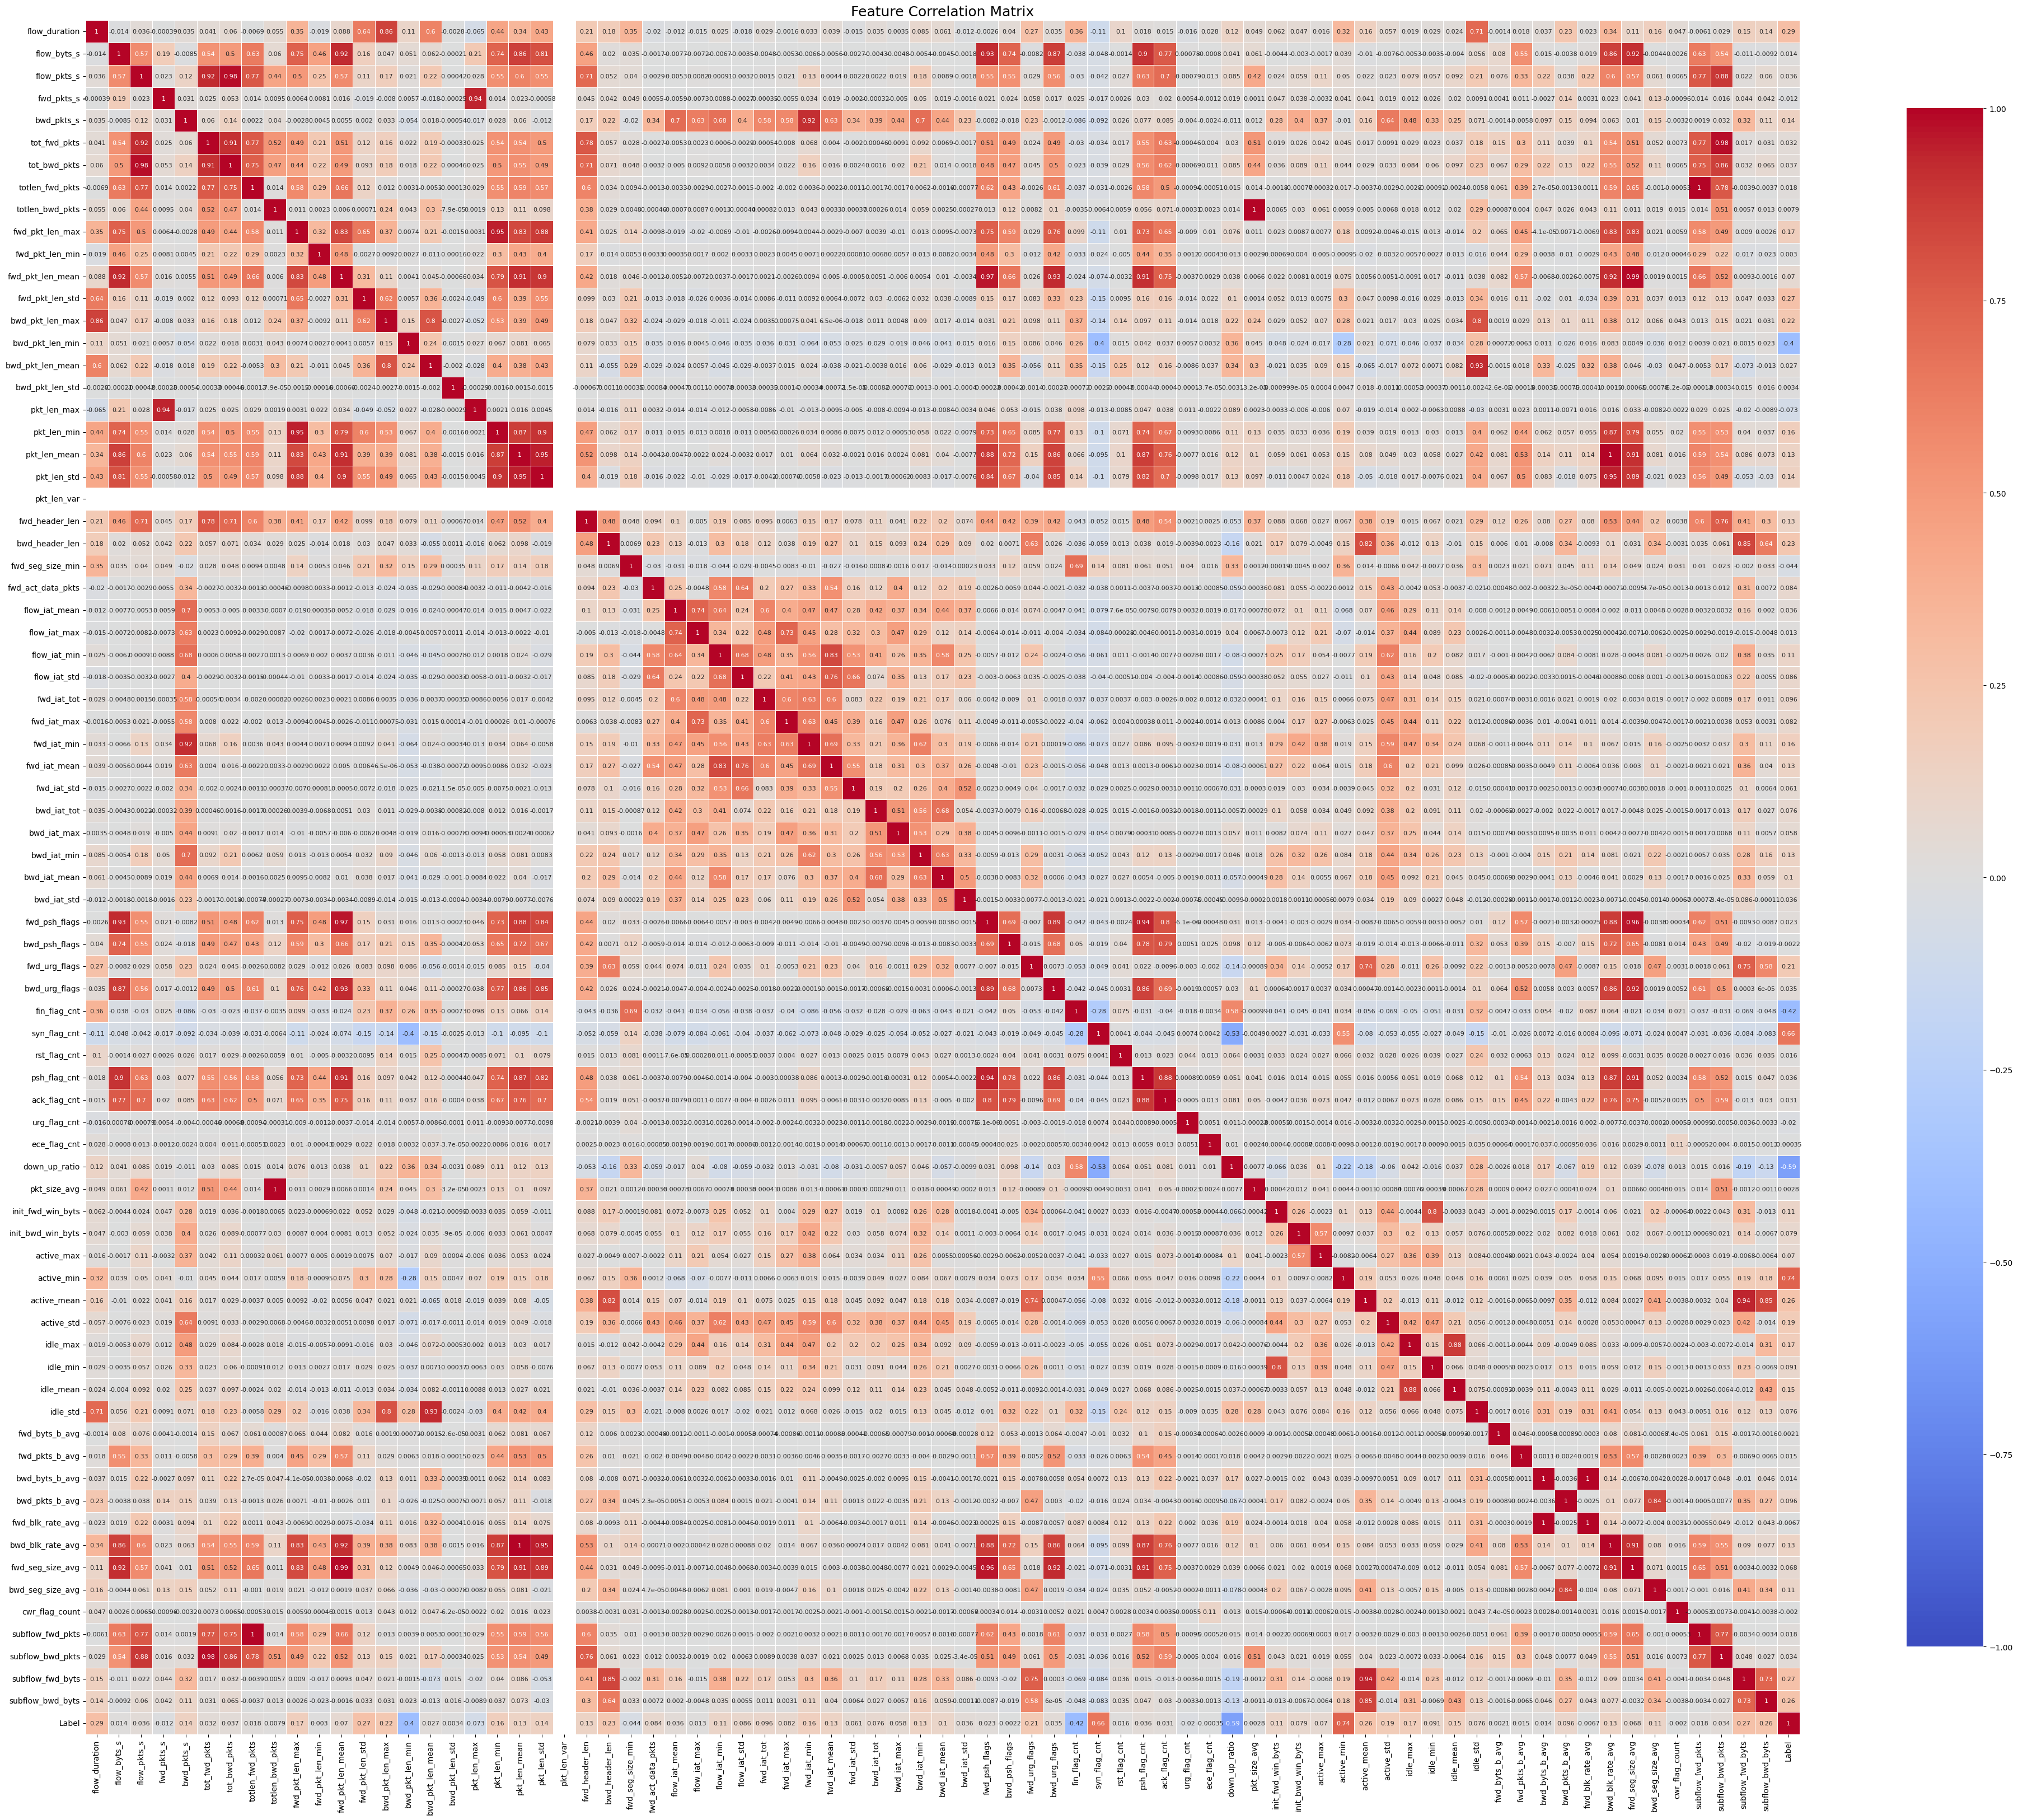

Top 20 highest correlations:
totlen_fwd_pkts   subflow_fwd_pkts    0.999979
subflow_fwd_pkts  totlen_fwd_pkts     0.999979
bwd_blk_rate_avg  pkt_len_mean        0.999817
pkt_len_mean      bwd_blk_rate_avg    0.999817
bwd_byts_b_avg    fwd_blk_rate_avg    0.997594
fwd_blk_rate_avg  bwd_byts_b_avg      0.997594
totlen_bwd_pkts   pkt_size_avg        0.996540
pkt_size_avg      totlen_bwd_pkts     0.996540
fwd_pkt_len_mean  fwd_seg_size_avg    0.990187
fwd_seg_size_avg  fwd_pkt_len_mean    0.990187
tot_fwd_pkts      subflow_bwd_pkts    0.983398
subflow_bwd_pkts  tot_fwd_pkts        0.983398
tot_bwd_pkts      flow_pkts_s         0.979279
flow_pkts_s       tot_bwd_pkts        0.979279
fwd_psh_flags     fwd_pkt_len_mean    0.967420
fwd_pkt_len_mean  fwd_psh_flags       0.967420
fwd_psh_flags     fwd_seg_size_avg    0.962799
fwd_seg_size_avg  fwd_psh_flags       0.962799
pkt_len_std       pkt_len_mean        0.947367
pkt_len_mean      pkt_len_std         0.947367
dtype: float64


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

#merged_df.rename(columns=COLUMN_MAPPING, inplace=True)
# List of features you provided
features = merged_df.columns

# Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()


plt.figure(figsize=(40, 35))  # Increase width and height to make boxes bigger

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={'size': 8}  # You can increase annotation font size if you want
)

plt.title('Feature Correlation Matrix', fontsize=18)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

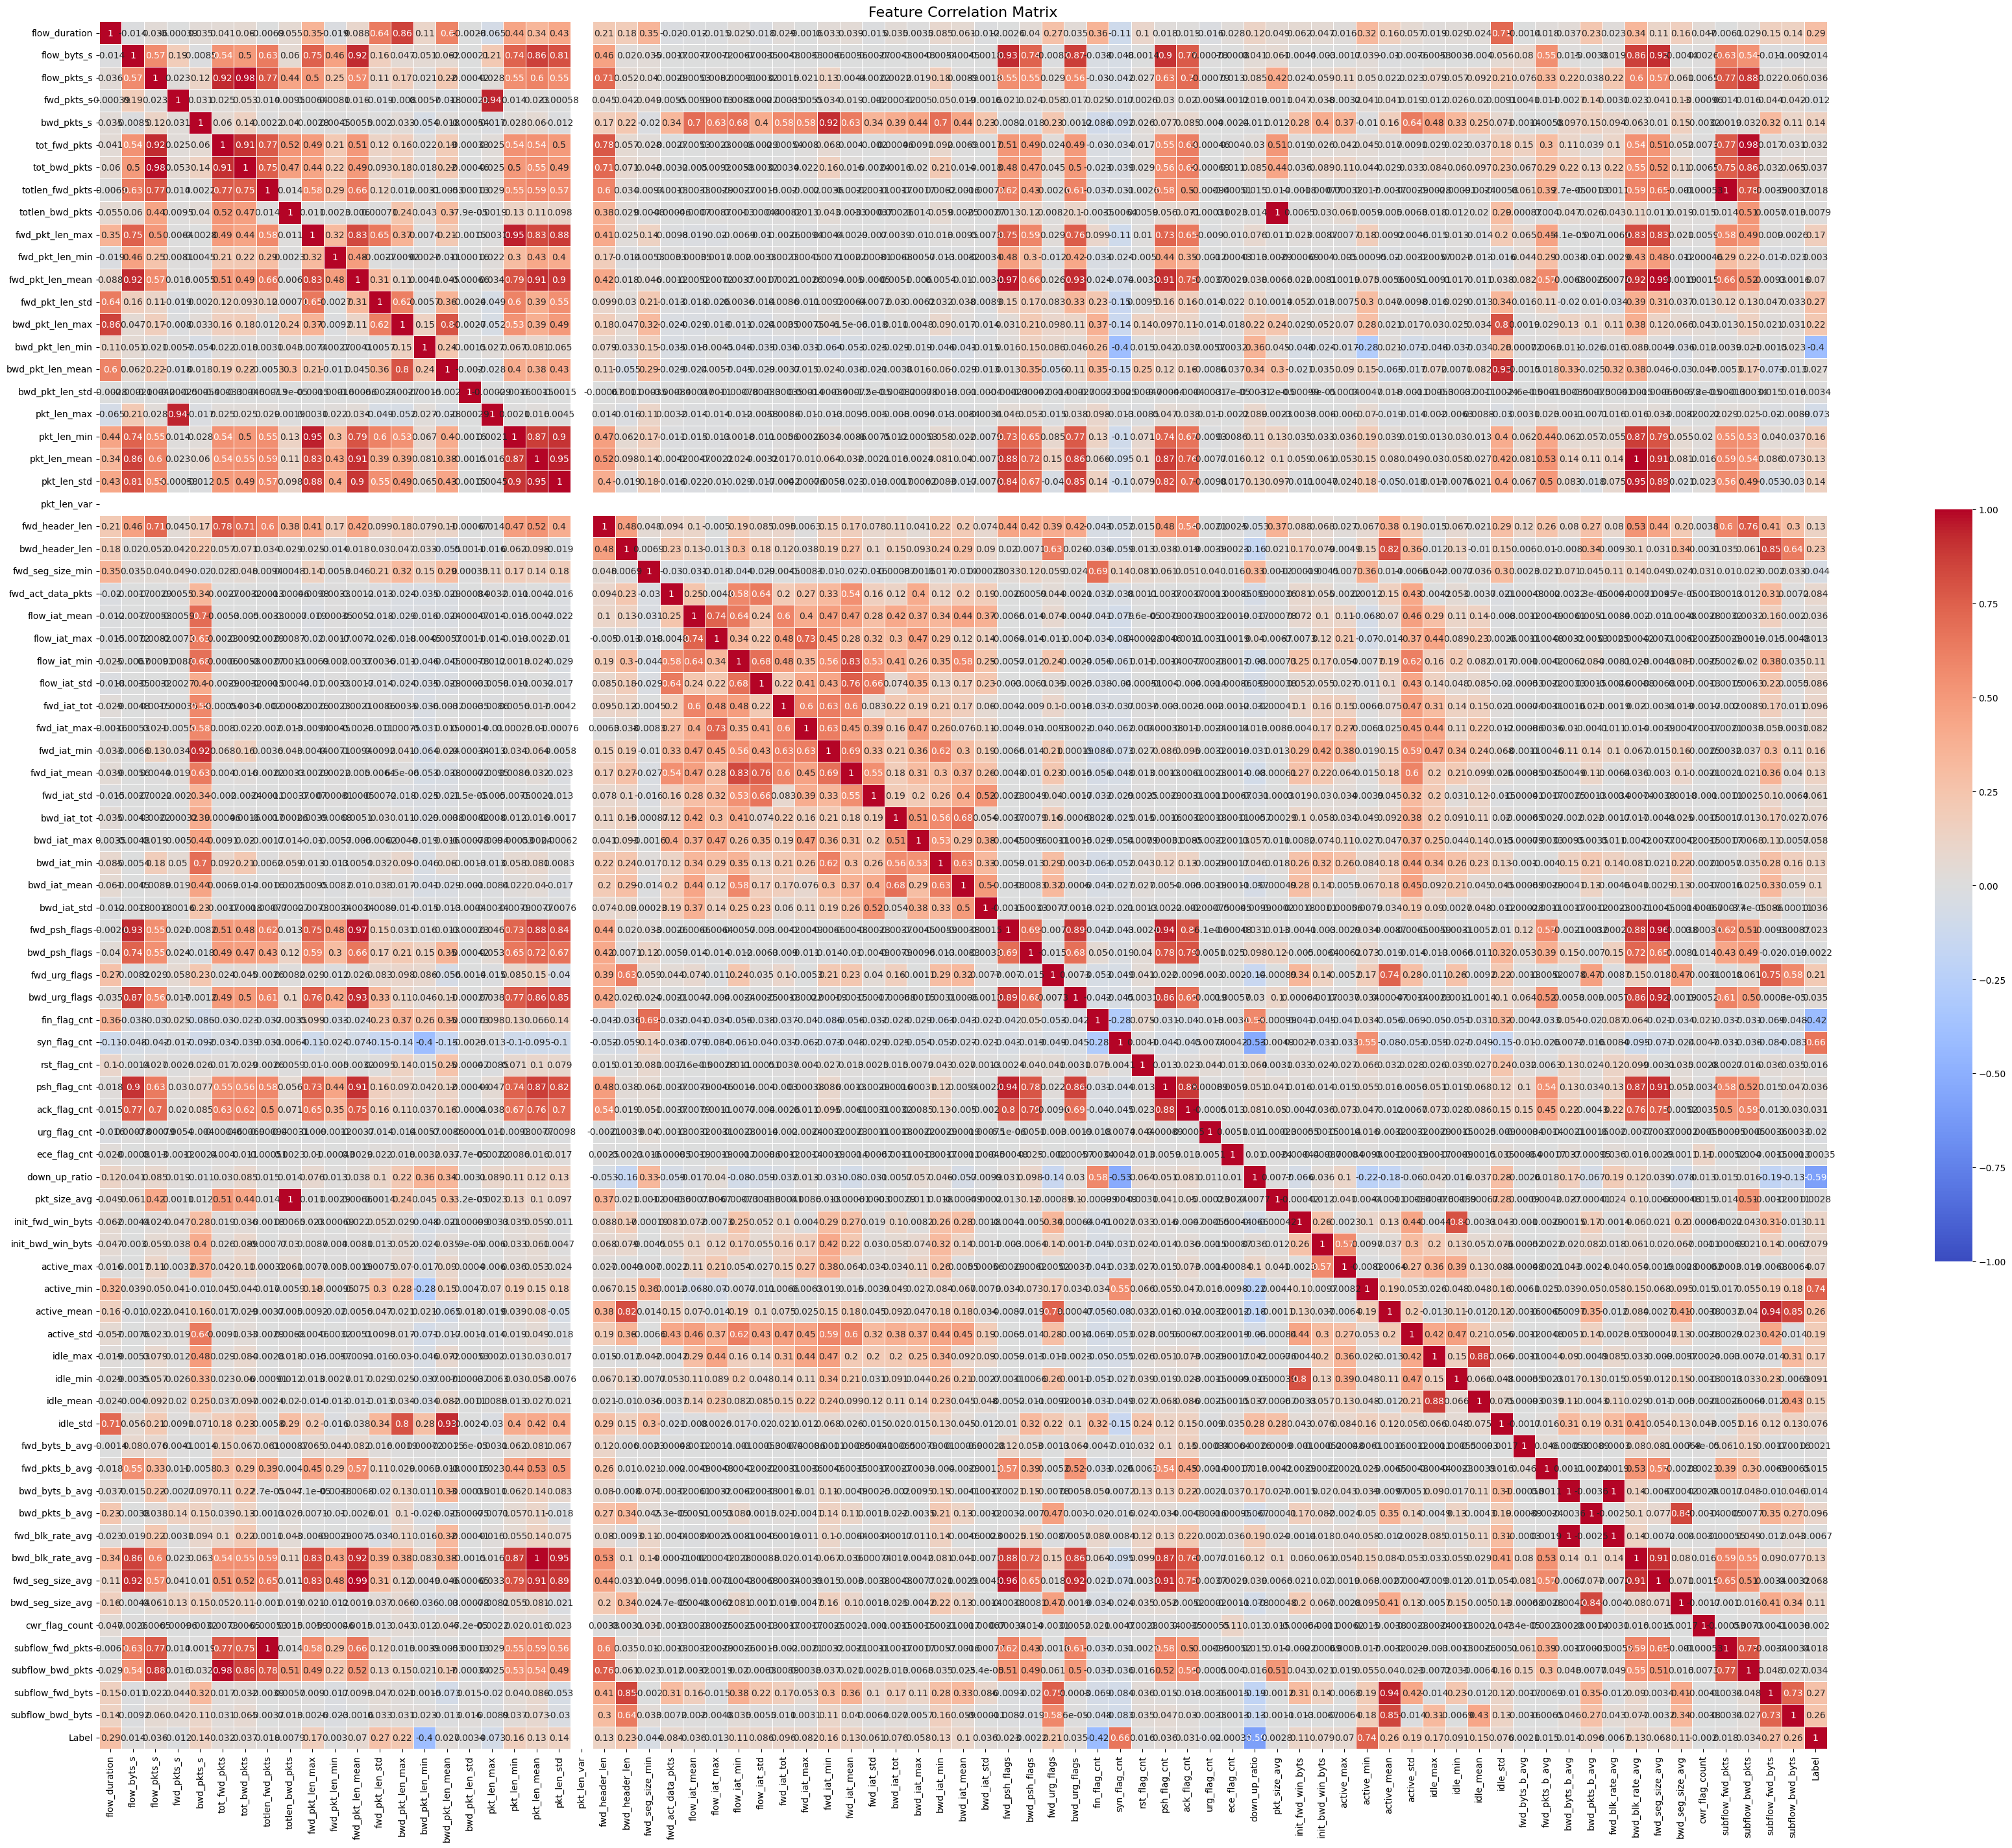

Top 20 highest correlations:
totlen_fwd_pkts   subflow_fwd_pkts    0.999979
subflow_fwd_pkts  totlen_fwd_pkts     0.999979
bwd_blk_rate_avg  pkt_len_mean        0.999817
pkt_len_mean      bwd_blk_rate_avg    0.999817
bwd_byts_b_avg    fwd_blk_rate_avg    0.997594
fwd_blk_rate_avg  bwd_byts_b_avg      0.997594
totlen_bwd_pkts   pkt_size_avg        0.996540
pkt_size_avg      totlen_bwd_pkts     0.996540
fwd_pkt_len_mean  fwd_seg_size_avg    0.990187
fwd_seg_size_avg  fwd_pkt_len_mean    0.990187
tot_fwd_pkts      subflow_bwd_pkts    0.983398
subflow_bwd_pkts  tot_fwd_pkts        0.983398
tot_bwd_pkts      flow_pkts_s         0.979279
flow_pkts_s       tot_bwd_pkts        0.979279
fwd_psh_flags     fwd_pkt_len_mean    0.967420
fwd_pkt_len_mean  fwd_psh_flags       0.967420
fwd_psh_flags     fwd_seg_size_avg    0.962799
fwd_seg_size_avg  fwd_psh_flags       0.962799
pkt_len_std       pkt_len_mean        0.947367
pkt_len_mean      pkt_len_std         0.947367
dtype: float64


In [15]:

# List of features you provided
features = merged_df.columns


# Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(35, 30))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.7,
            cbar_kws={"shrink": 0.4},
            annot=True,
            annot_kws={'size':10})


plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

In [16]:
# Columns that should never be dropped
protected_cols = ['Label']

# Use only feature columns for correlation analysis
features_df = merged_df.drop(columns=protected_cols, errors='ignore')

# Compute absolute correlation matrix
corr_matrix = features_df.corr().abs()

# Create upper triangle of the correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Set correlation threshold
threshold = 0.7

# Find highly correlated features
to_drop = [
    column for column in upper.columns
    if any(upper[column] >= threshold)
]

print("Highly correlated features to drop (correlation ≥ 0.7):")
print(to_drop)

# Drop correlated features BUT keep protected columns
reduced_df = merged_df.drop(columns=to_drop, errors='ignore')

# Shapes before and after
print("Original shape:", merged_df.shape)
print("Reduced shape:", reduced_df.shape)


Highly correlated features to drop (correlation ≥ 0.7):
['tot_fwd_pkts', 'tot_bwd_pkts', 'totlen_fwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'bwd_pkt_len_max', 'bwd_pkt_len_mean', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_std', 'fwd_header_len', 'flow_iat_mean', 'flow_iat_max', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_psh_flags', 'bwd_psh_flags', 'bwd_urg_flags', 'psh_flag_cnt', 'ack_flag_cnt', 'pkt_size_avg', 'active_mean', 'idle_min', 'idle_mean', 'idle_std', 'fwd_blk_rate_avg', 'bwd_blk_rate_avg', 'fwd_seg_size_avg', 'bwd_seg_size_avg', 'subflow_fwd_pkts', 'subflow_bwd_pkts', 'subflow_fwd_byts', 'subflow_bwd_byts']
Original shape: (246632, 77)
Reduced shape: (246632, 42)


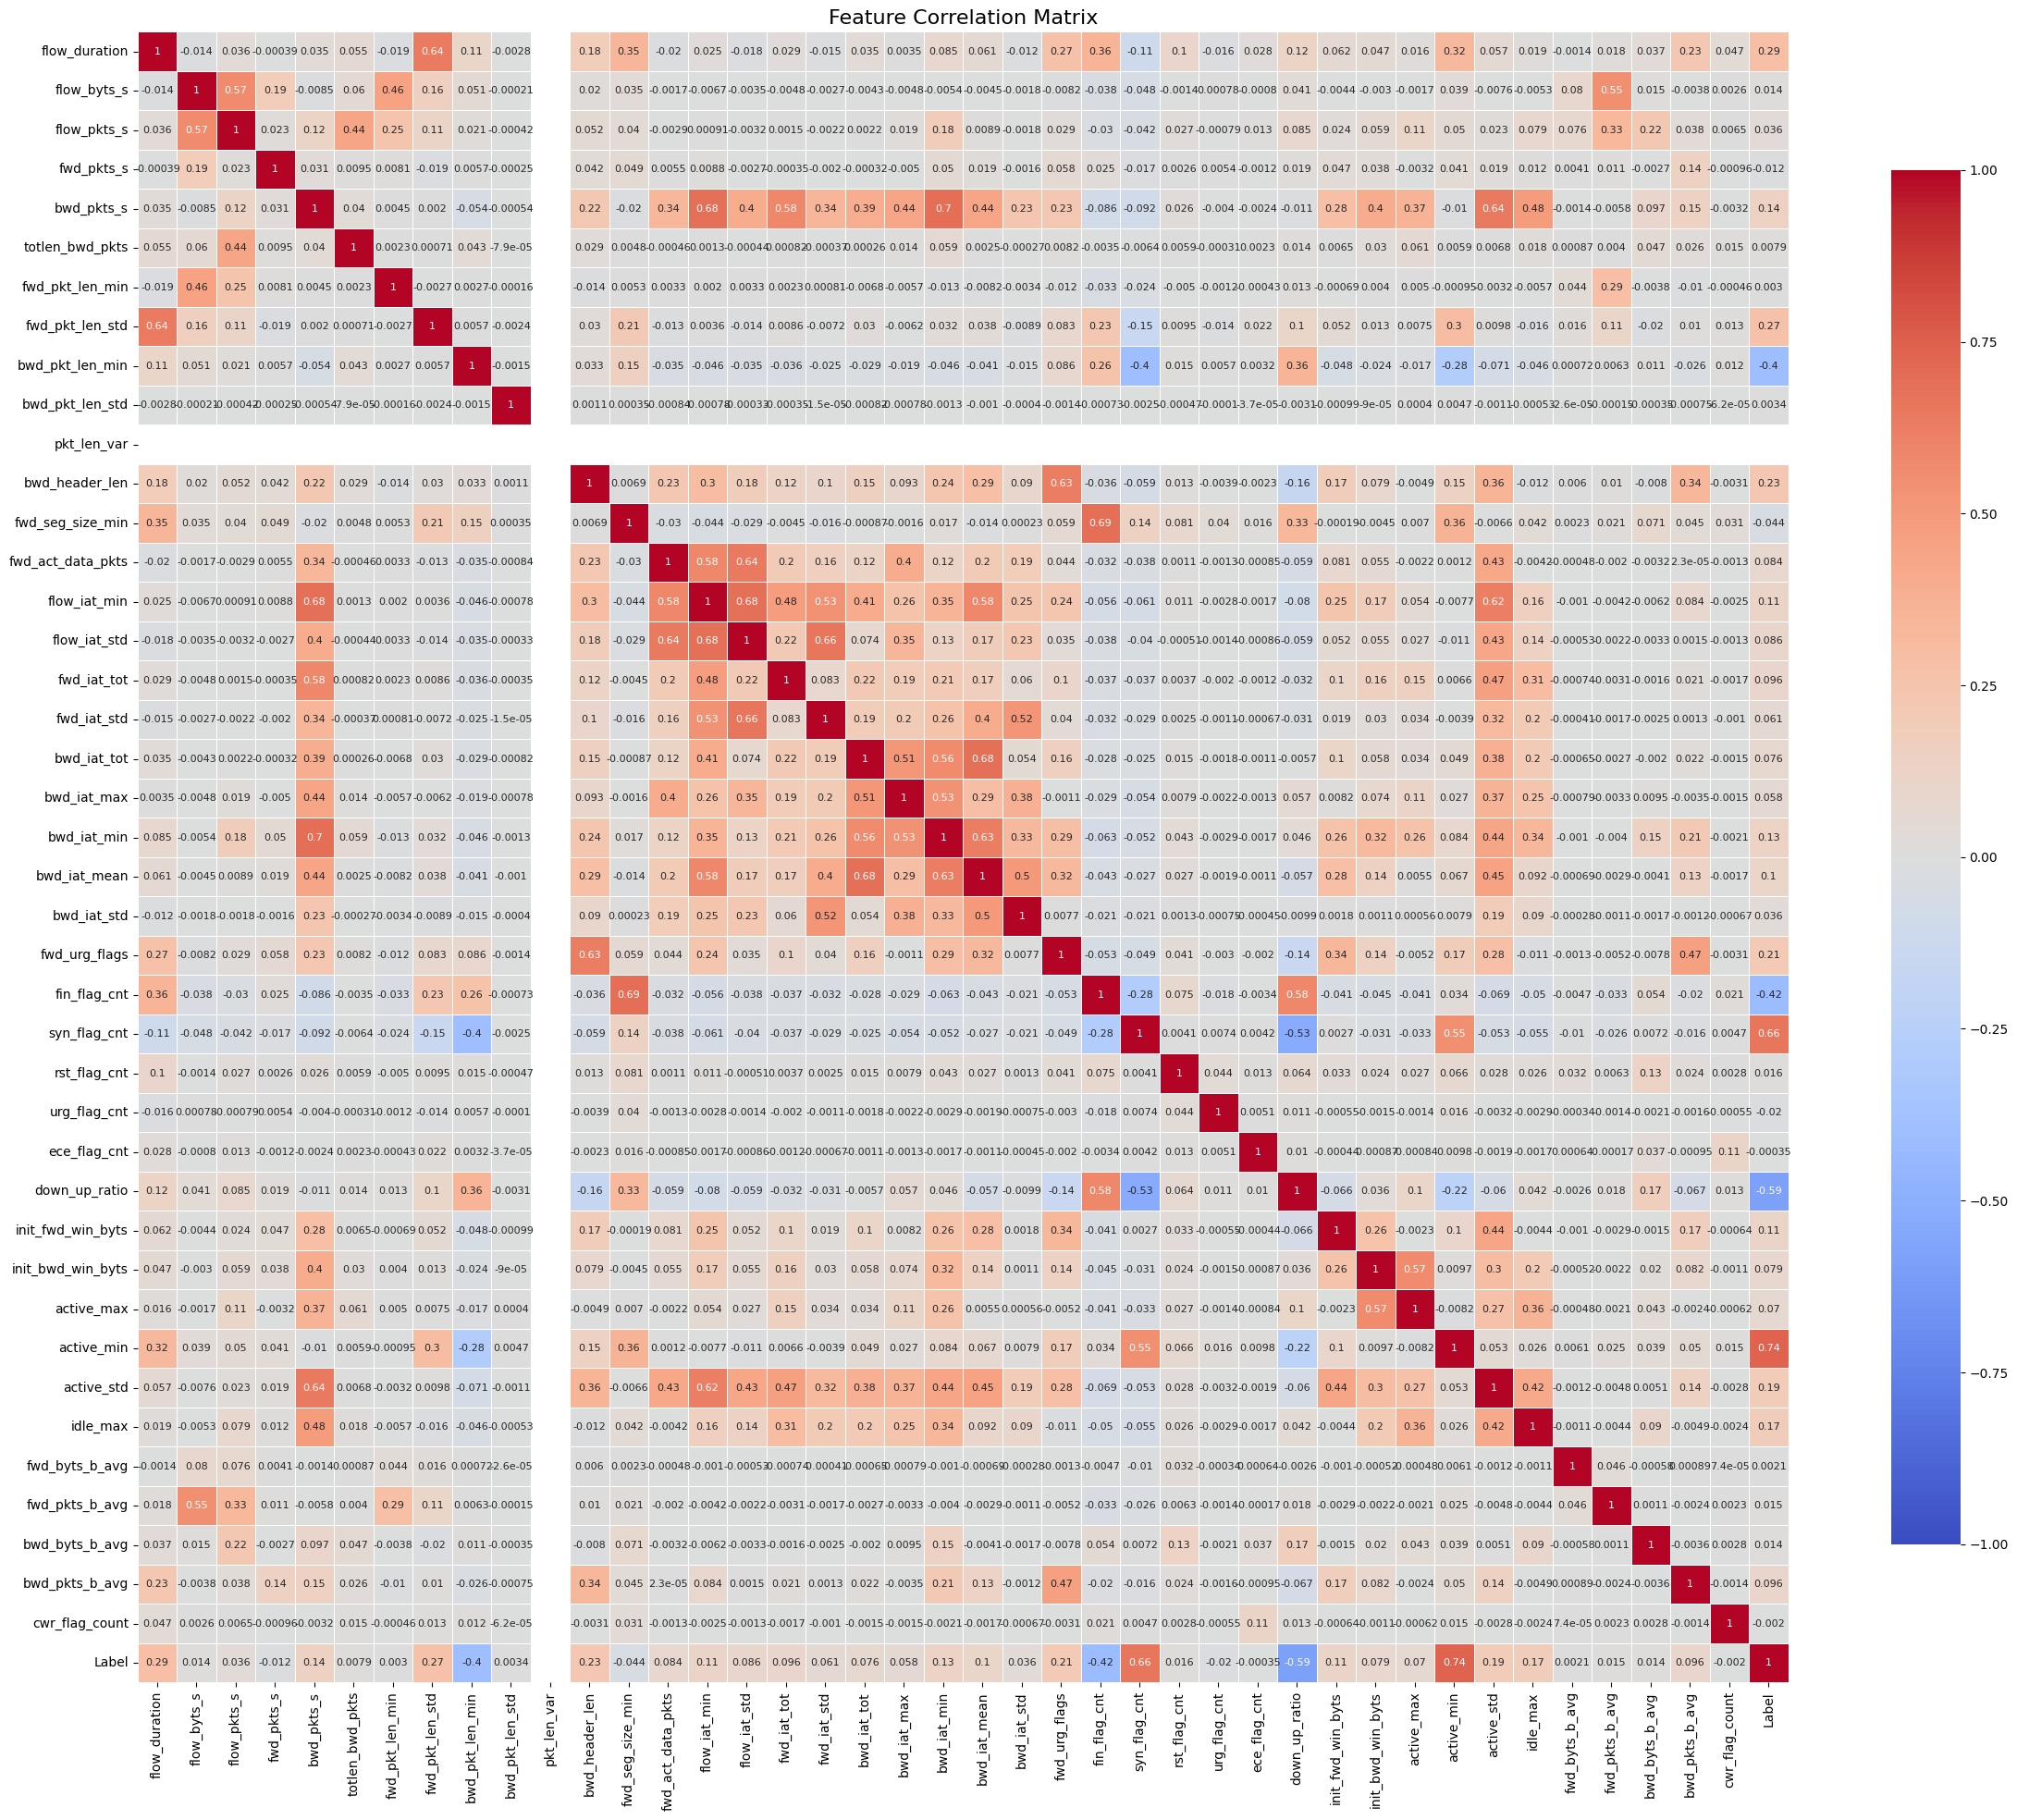

Top 20 highest correlations:
Label              active_min           0.735376
active_min         Label                0.735376
bwd_pkts_s         bwd_iat_min          0.695224
bwd_iat_min        bwd_pkts_s           0.695224
fwd_seg_size_min   fin_flag_cnt         0.692563
fin_flag_cnt       fwd_seg_size_min     0.692563
bwd_iat_tot        bwd_iat_mean         0.684128
bwd_iat_mean       bwd_iat_tot          0.684128
flow_iat_std       flow_iat_min         0.683833
flow_iat_min       flow_iat_std         0.683833
                   bwd_pkts_s           0.680966
bwd_pkts_s         flow_iat_min         0.680966
flow_iat_std       fwd_iat_std          0.661628
fwd_iat_std        flow_iat_std         0.661628
syn_flag_cnt       Label                0.660870
Label              syn_flag_cnt         0.660870
flow_iat_std       fwd_act_data_pkts    0.643117
fwd_act_data_pkts  flow_iat_std         0.643117
active_std         bwd_pkts_s           0.642786
bwd_pkts_s         active_std           

In [17]:
# List of features you provided
features=reduced_df.columns
    # Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(24, 20))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            annot=True,
            annot_kws={'size':8})

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

In [18]:

# Keep only numeric columns from merged_df
numeric_df = reduced_df.select_dtypes(include=[np.number])

# Compute correlation matrix on numeric data
correlation_matrix = numeric_df.corr()

# Choose correlation column: 'Label' or 'Label_encoded'
target_column = 'Label'  # or 'Label_encoded' if using encoded labels

# Get correlation of all features with the label column
label_corr = correlation_matrix[target_column]

# Set threshold
threshold = 0.03

# Keep only features with abs(correlation) > threshold
features_to_keep = label_corr[abs(label_corr) > threshold].index.tolist()

# Ensure the target column is included
if target_column not in features_to_keep:
    features_to_keep.append(target_column)

# Filter original merged_df using the selected numeric features
merged_df = merged_df[features_to_keep]

# Print results
print("Kept features:", features_to_keep)
print("Filtered shape:", merged_df.shape)


Kept features: ['flow_duration', 'flow_pkts_s', 'bwd_pkts_s', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_header_len', 'fwd_seg_size_min', 'fwd_act_data_pkts', 'flow_iat_min', 'flow_iat_std', 'fwd_iat_tot', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'fwd_urg_flags', 'fin_flag_cnt', 'syn_flag_cnt', 'down_up_ratio', 'init_fwd_win_byts', 'init_bwd_win_byts', 'active_max', 'active_min', 'active_std', 'idle_max', 'bwd_pkts_b_avg', 'Label']
Filtered shape: (246632, 29)


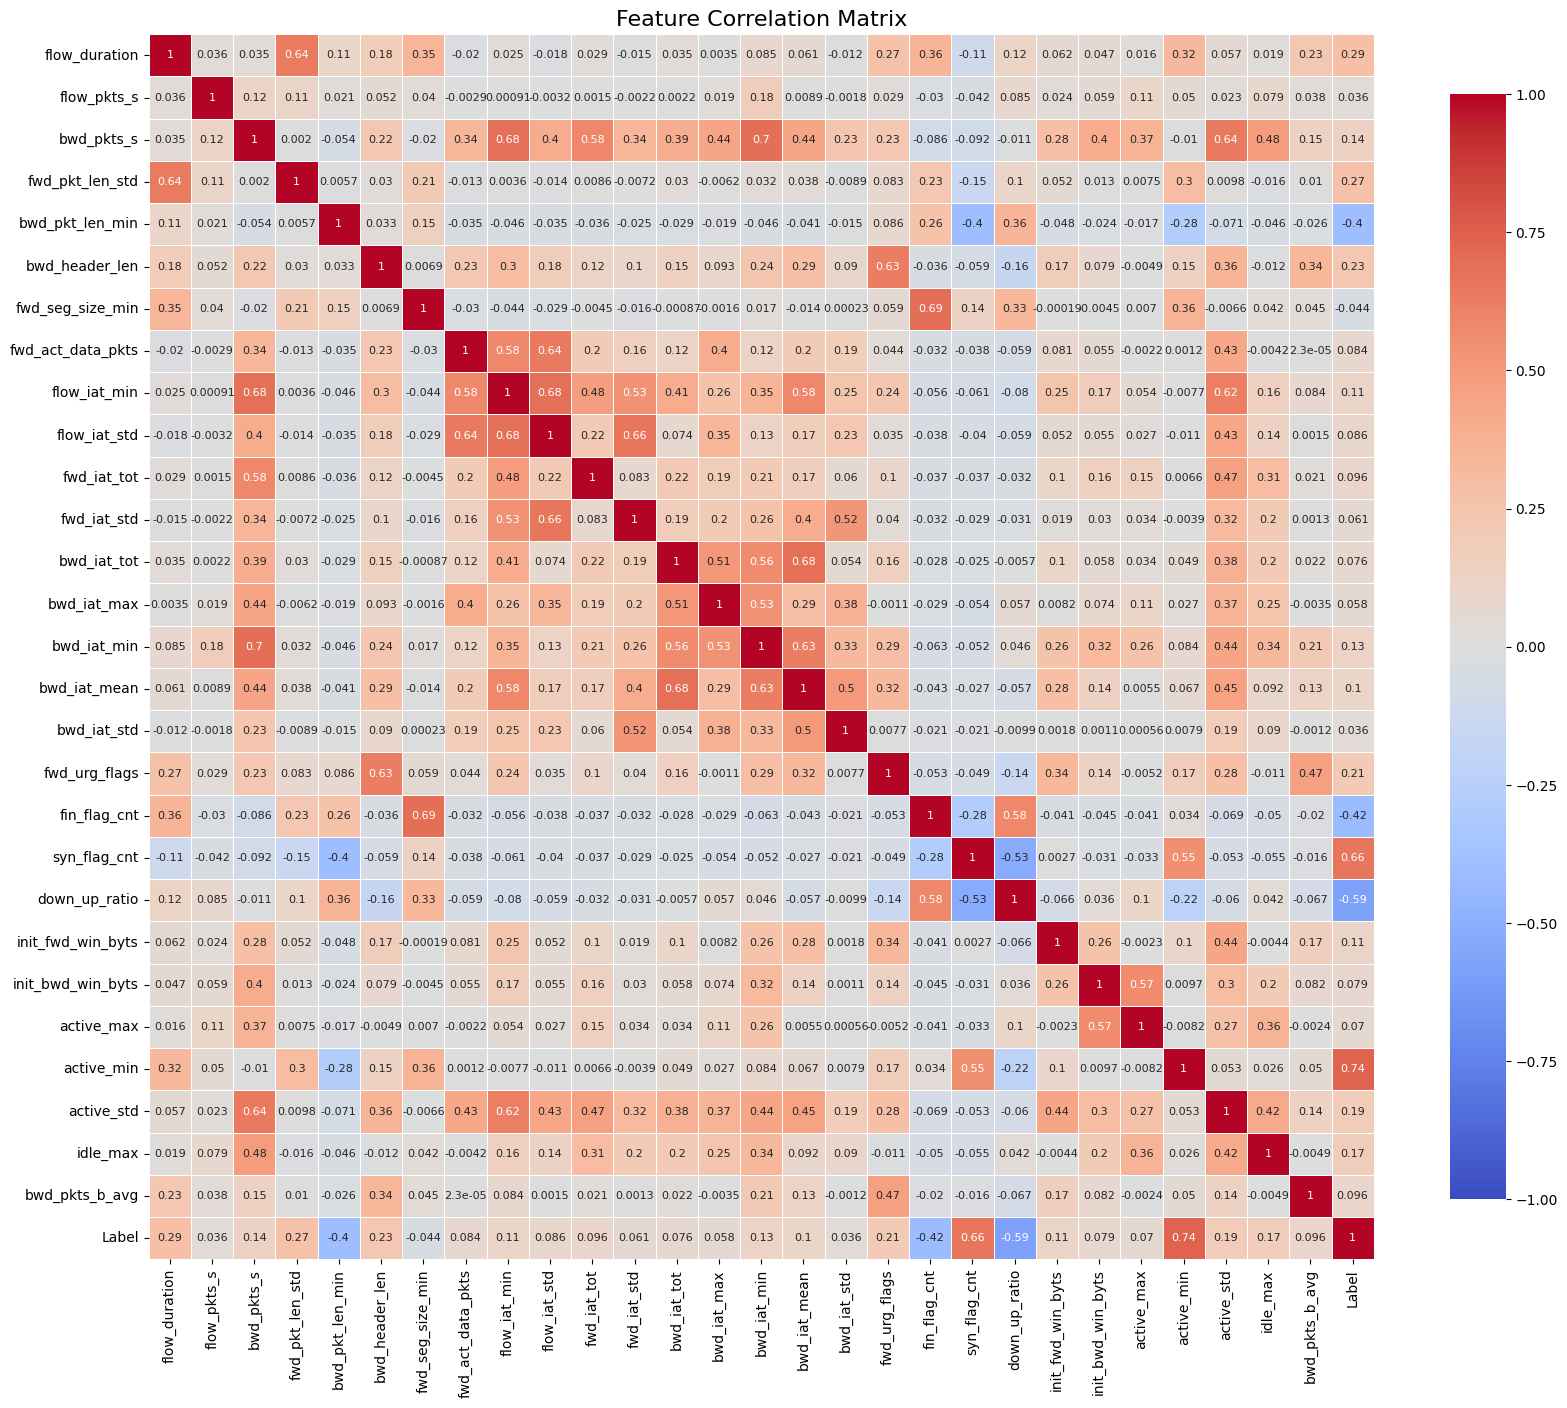

Top 20 highest correlations:
active_min         Label                0.735376
Label              active_min           0.735376
bwd_pkts_s         bwd_iat_min          0.695224
bwd_iat_min        bwd_pkts_s           0.695224
fwd_seg_size_min   fin_flag_cnt         0.692563
fin_flag_cnt       fwd_seg_size_min     0.692563
bwd_iat_mean       bwd_iat_tot          0.684128
bwd_iat_tot        bwd_iat_mean         0.684128
flow_iat_min       flow_iat_std         0.683833
flow_iat_std       flow_iat_min         0.683833
bwd_pkts_s         flow_iat_min         0.680966
flow_iat_min       bwd_pkts_s           0.680966
flow_iat_std       fwd_iat_std          0.661628
fwd_iat_std        flow_iat_std         0.661628
syn_flag_cnt       Label                0.660870
Label              syn_flag_cnt         0.660870
flow_iat_std       fwd_act_data_pkts    0.643117
fwd_act_data_pkts  flow_iat_std         0.643117
active_std         bwd_pkts_s           0.642786
bwd_pkts_s         active_std           

In [19]:
# List of features you provided
features=merged_df.columns
    # Select only numeric columns for correlation (excluding categorical like 'Flow ID', 'Protocol', 'Label')
numeric_features = [f for f in features if f not in []]

# Calculate correlation matrix
corr_matrix = merged_df[numeric_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(17, 15))

# Create a heatmap
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            annot=True,
            annot_kws={'size':8})

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you want to see specific high correlations
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # Remove self-correlations
print("Top 20 highest correlations:")
print(high_corr.head(20))

Remaining samples after outlier removal: 239233

RANDOM FOREST – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     42640
         FTP       1.00      1.00      1.00     32690
       HTTPS       0.98      0.99      0.99     17700
         SSH       1.00      0.99      1.00     34025
         VPN       1.00      1.00      1.00     39624
       other       0.99      1.00      0.99       784

    accuracy                           1.00    167463
   macro avg       1.00      1.00      1.00    167463
weighted avg       1.00      1.00      1.00    167463



<Figure size 800x600 with 0 Axes>

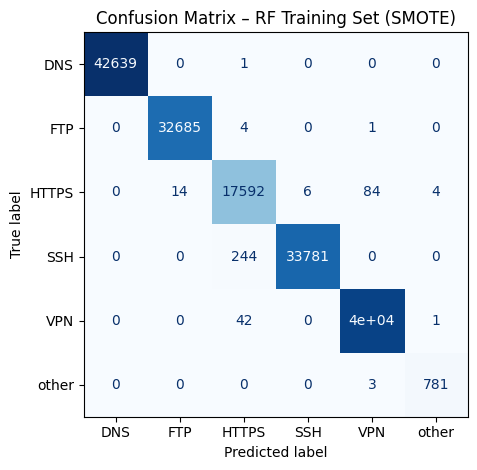


RANDOM FOREST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18274
         FTP       1.00      1.00      1.00     14010
       HTTPS       0.98      0.99      0.99      7586
         SSH       1.00      0.99      1.00     14582
         VPN       1.00      1.00      1.00     16982
       other       1.00      1.00      1.00       336

    accuracy                           1.00     71770
   macro avg       1.00      1.00      1.00     71770
weighted avg       1.00      1.00      1.00     71770



<Figure size 800x600 with 0 Axes>

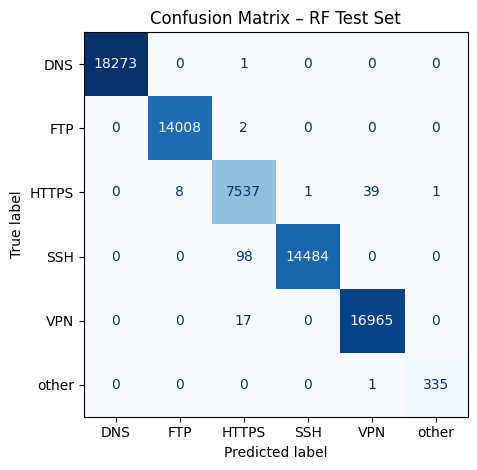


Random Forest Test Accuracy: 0.9977


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import Pipeline

# from imblearn.over_sampling import SMOTE


# =========================================================
# 1. BASIC CLEANING
# =========================================================

merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

# =========================================================
# 5. RANDOM FOREST PIPELINE
# =========================================================

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),
    ("rf", RandomForestClassifier(
        max_depth=4,
        random_state=3,
     
    ))
])

rf_pipeline.fit(X_train, y_train)

# =========================================================
# 7. TRAINING SET EVALUATION (SMOTE DATA)
# =========================================================

y_train_pred = rf_pipeline.predict(X_train)

print("\nRANDOM FOREST – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Training Set (SMOTE)")
plt.tight_layout()
plt.show()


# =========================================================
# 8. TEST SET EVALUATION
# =========================================================

y_test_pred = rf_pipeline.predict(X_test)

print("\nRANDOM FOREST – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Test Set")
plt.tight_layout()
plt.show()


# =========================================================
# 9. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nRandom Forest Test Accuracy: {test_accuracy:.4f}")

In [21]:
# =========================================================
# 10. SAVE MODEL + SELECTED FEATURES (OPTIONAL)
# =========================================================
import joblib
joblib.dump(rf_pipeline, "RF_model.pkl")

# 1️ Save all features used to train the model (before SelectKBest)
all_features = X_train.columns.tolist()  # original numeric columns
joblib.dump(all_features, "RF_features.pkl")

print(f"Saved RF_model.pkl and RF_features.pkl (all {len(all_features)} features)")
# import joblib

joblib.dump(rf_pipeline, "RF_model.pkl")

selected_features = X_train.columns.tolist() 

joblib.dump(selected_features, "RF_features.pkl")

print("\nSaved RF_model.pkl and RF_features.pkl")

Saved RF_model.pkl and RF_features.pkl (all 28 features)

Saved RF_model.pkl and RF_features.pkl


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
import joblib

# ===============================
# 1. BASIC CLEANING
# ===============================
merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]

# ===============================
# 2. OUTLIER REMOVAL
# ===============================
iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]
print(f"Remaining samples after outlier removal: {len(X)}")

# ===============================
# 3. TRAIN–TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)


mlp_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),
    # ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=42
    ))
])

print("\nRunning MLP...")
mlp_pipeline.fit(X_train, y_train)

# ---- Evaluation ----
y_test_pred_mlp = mlp_pipeline.predict(X_test)

print("\nMLP – TEST SET PERFORMANCE")
print(classification_report(
    y_test,
    y_test_pred_mlp,
    target_names=label_encoder.classes_.astype(str)
))

print("MLP Accuracy:", accuracy_score(y_test, y_test_pred_mlp))

joblib.dump(mlp_pipeline, "MLP_model.pkl")
print("Saved MLP_model.pkl")


Remaining samples after outlier removal: 239233

Running MLP...

MLP – TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18274
         FTP       0.00      0.00      0.00     14010
       HTTPS       0.99      0.33      0.49      7586
         SSH       0.29      1.00      0.45     14582
         VPN       0.78      0.00      0.01     16982
       other       1.00      0.91      0.95       336

    accuracy                           0.50     71770
   macro avg       0.68      0.54      0.48     71770
weighted avg       0.61      0.50      0.40     71770

MLP Accuracy: 0.49719938693047233
Saved MLP_model.pkl


In [23]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
import joblib

# ===============================
# 1. BASIC CLEANING
# ===============================
merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]

# ===============================
# 2. OUTLIER REMOVAL
# ===============================
iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]
print(f"Remaining samples after outlier removal: {len(X)}")

# ===============================
# 3. TRAIN–TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),
    ("xgb", XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("\nRunning XGBoost...")
xgb_pipeline.fit(X_train, y_train)

# ---- Evaluation ----
y_test_pred_xgb = xgb_pipeline.predict(X_test)

print("\nXGBOOST – TEST SET PERFORMANCE")
print(classification_report(
    y_test,
    y_test_pred_xgb,
    target_names=label_encoder.classes_.astype(str)
))

print("XGBoost Accuracy:", accuracy_score(y_test, y_test_pred_xgb))

joblib.dump(xgb_pipeline, "XGB_model.pkl")
print("Saved XGB_model.pkl")

Remaining samples after outlier removal: 239233

Running XGBoost...

XGBOOST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18274
         FTP       1.00      1.00      1.00     14010
       HTTPS       1.00      0.99      1.00      7586
         SSH       1.00      1.00      1.00     14582
         VPN       1.00      1.00      1.00     16982
       other       1.00      1.00      1.00       336

    accuracy                           1.00     71770
   macro avg       1.00      1.00      1.00     71770
weighted avg       1.00      1.00      1.00     71770

XGBoost Accuracy: 0.9993033300822071
Saved XGB_model.pkl


Remaining samples after outlier removal: 239233

Training KNN model...

KNN – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42640
           1       1.00      1.00      1.00     32690
           2       1.00      1.00      1.00     17700
           3       1.00      1.00      1.00     34025
           4       1.00      1.00      1.00     39624
           5       0.99      0.99      0.99       784

    accuracy                           1.00    167463
   macro avg       1.00      1.00      1.00    167463
weighted avg       1.00      1.00      1.00    167463



<Figure size 800x600 with 0 Axes>

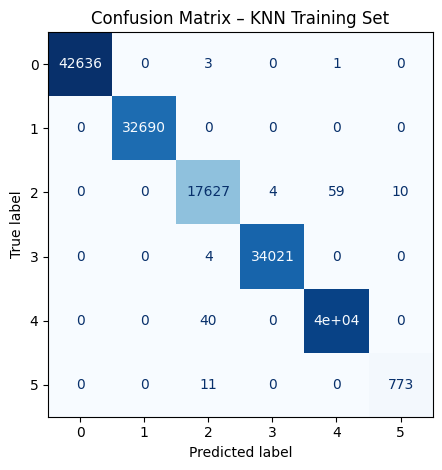


KNN – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18274
           1       1.00      1.00      1.00     14010
           2       1.00      0.99      1.00      7586
           3       1.00      1.00      1.00     14582
           4       1.00      1.00      1.00     16982
           5       0.99      0.99      0.99       336

    accuracy                           1.00     71770
   macro avg       1.00      1.00      1.00     71770
weighted avg       1.00      1.00      1.00     71770



<Figure size 800x600 with 0 Axes>

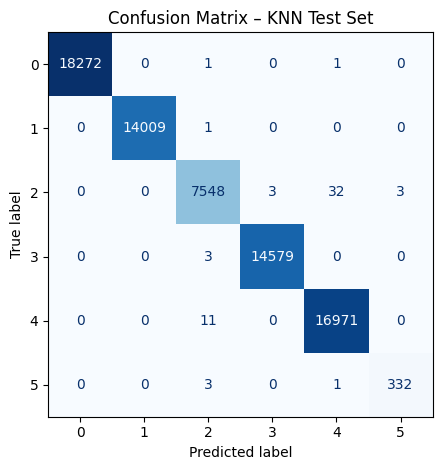


KNN Test Accuracy: 0.9992

Saved KNN_model.pkl and KNN_features.pkl


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

import joblib

# ===============================
# 1. BASIC CLEANING
# ===============================
merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]

# ===============================
# 2. OUTLIER REMOVAL
# ===============================
iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]
print(f"Remaining samples after outlier removal: {len(X)}")

# ===============================
# 3. TRAIN–TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# ===============================
# 4. KNN PIPELINE
# ===============================
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),  # choose top 20 features
    ("knn", KNeighborsClassifier(
        n_neighbors=3,   # you can tune this
        weights='uniform',  # or 'distance'
        metric='minkowski', # default
        p=2,  # Euclidean distance
        n_jobs=-1
    ))
])

# ===============================
# 5. TRAIN KNN MODEL
# ===============================
print("\nTraining KNN model...")
knn_pipeline.fit(X_train, y_train)

# ===============================
# 6. TRAINING SET EVALUATION
# ===============================
y_train_pred = knn_pipeline.predict(X_train)

print("\nKNN – TRAINING SET PERFORMANCE")
print(classification_report(y_train, y_train_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Training Set")
plt.tight_layout()
plt.show()

# ===============================
# 7. TEST SET EVALUATION
# ===============================
y_test_pred = knn_pipeline.predict(X_test)

print("\nKNN – TEST SET PERFORMANCE")
print(classification_report(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Test Set")
plt.tight_layout()
plt.show()

# ===============================
# 8. FINAL ACCURACY
# ===============================
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nKNN Test Accuracy: {test_accuracy:.4f}")

# ===============================
# 9. SAVE MODEL + SELECTED FEATURES
# ===============================
joblib.dump(knn_pipeline, "KNN_model.pkl")

# Save selected feature names
imputer = knn_pipeline.named_steps["imputer"]
selector = knn_pipeline.named_steps["select"]

feature_names = imputer.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

joblib.dump(selected_features.tolist(), "KNN_features.pkl")

print("\nSaved KNN_model.pkl and KNN_features.pkl")


Remaining samples after outlier removal: 239233

Training Logistic Regression model...


/home/znb/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



LOGISTIC REGRESSION – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42640
           1       1.00      1.00      1.00     32690
           2       0.99      0.97      0.98     17700
           3       0.99      1.00      0.99     34025
           4       1.00      1.00      1.00     39624
           5       0.96      0.94      0.95       784

    accuracy                           1.00    167463
   macro avg       0.99      0.98      0.99    167463
weighted avg       1.00      1.00      1.00    167463



<Figure size 800x600 with 0 Axes>

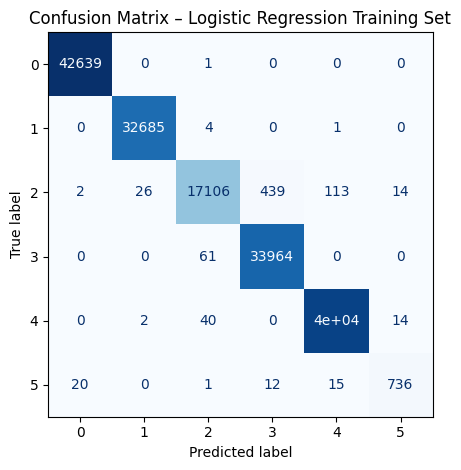


LOGISTIC REGRESSION – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18274
           1       1.00      1.00      1.00     14010
           2       0.99      0.97      0.98      7586
           3       0.99      1.00      0.99     14582
           4       1.00      1.00      1.00     16982
           5       0.97      0.93      0.95       336

    accuracy                           1.00     71770
   macro avg       0.99      0.98      0.99     71770
weighted avg       1.00      1.00      1.00     71770



<Figure size 800x600 with 0 Axes>

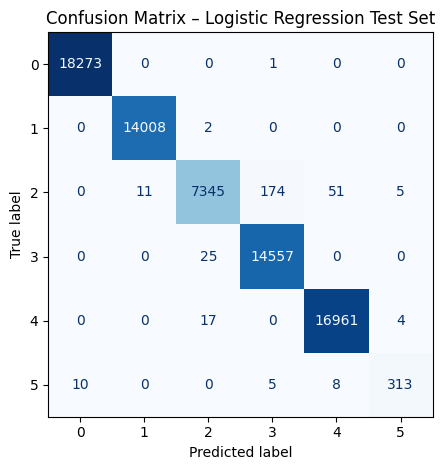


Logistic Regression Test Accuracy: 0.9956

Saved LogisticRegression_model.pkl and LogisticRegression_features.pkl


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import joblib

# ===============================
# 1. BASIC CLEANING
# ===============================
merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]

# ===============================
# 2. OUTLIER REMOVAL
# ===============================
iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]
print(f"Remaining samples after outlier removal: {len(X)}")

# ===============================
# 3. TRAIN–TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# ===============================
# 4. LOGISTIC REGRESSION PIPELINE
# ===============================
logreg_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),  # select top 20 features
    ("scaler", StandardScaler()),  # IMPORTANT for Logistic Regression
    ("logreg", LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        multi_class="auto",
        random_state=42,
        n_jobs=-1
    ))
])

# ===============================
# 5. TRAIN MODEL
# ===============================
print("\nTraining Logistic Regression model...")
logreg_pipeline.fit(X_train, y_train)

# ===============================
# 6. TRAINING SET EVALUATION
# ===============================
y_train_pred = logreg_pipeline.predict(X_train)

print("\nLOGISTIC REGRESSION – TRAINING SET PERFORMANCE")
print(classification_report(y_train, y_train_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – Logistic Regression Training Set")
plt.tight_layout()
plt.show()

# ===============================
# 7. TEST SET EVALUATION
# ===============================
y_test_pred = logreg_pipeline.predict(X_test)

print("\nLOGISTIC REGRESSION – TEST SET PERFORMANCE")
print(classification_report(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – Logistic Regression Test Set")
plt.tight_layout()
plt.show()

# ===============================
# 8. FINAL ACCURACY
# ===============================
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nLogistic Regression Test Accuracy: {test_accuracy:.4f}")

# ===============================
# 9. SAVE MODEL + SELECTED FEATURES
# ===============================
joblib.dump(logreg_pipeline, "LogisticRegression_model.pkl")

# Save selected feature names
imputer = logreg_pipeline.named_steps["imputer"]
selector = logreg_pipeline.named_steps["select"]

feature_names = imputer.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

joblib.dump(selected_features.tolist(), "LogisticRegression_features.pkl")

print("\nSaved LogisticRegression_model.pkl and LogisticRegression_features.pkl")


Remaining samples after outlier removal: 239233

Training SVM model...

SVM – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42640
           1       1.00      1.00      1.00     32690
           2       1.00      0.99      0.99     17700
           3       1.00      1.00      1.00     34025
           4       1.00      1.00      1.00     39624
           5       1.00      0.99      1.00       784

    accuracy                           1.00    167463
   macro avg       1.00      1.00      1.00    167463
weighted avg       1.00      1.00      1.00    167463



<Figure size 800x600 with 0 Axes>

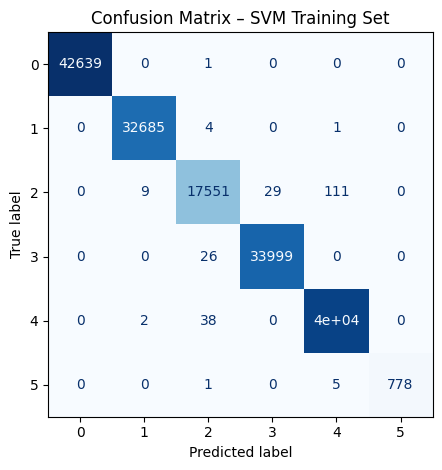


SVM – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18274
           1       1.00      1.00      1.00     14010
           2       1.00      0.99      0.99      7586
           3       1.00      1.00      1.00     14582
           4       1.00      1.00      1.00     16982
           5       0.99      0.99      0.99       336

    accuracy                           1.00     71770
   macro avg       1.00      1.00      1.00     71770
weighted avg       1.00      1.00      1.00     71770



<Figure size 800x600 with 0 Axes>

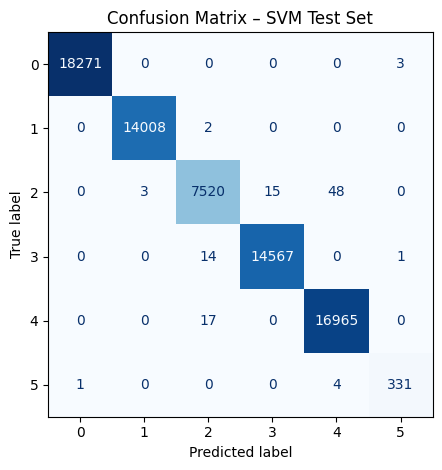


SVM Test Accuracy: 0.9985

Saved SVM_model.pkl and SVM_features.pkl


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

import joblib

# ===============================
# 1. BASIC CLEANING
# ===============================
merged_df = merged_df.dropna(subset=["Label"])
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

X = merged_df.drop(columns=["Label"]).select_dtypes(include=[np.number])
y = merged_df["Label"]

# ===============================
# 2. OUTLIER REMOVAL
# ===============================
iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

X_imputed = SimpleImputer(strategy="mean").fit_transform(X)
mask = iso.fit_predict(X_imputed) == 1

X, y = X[mask], y[mask]
print(f"Remaining samples after outlier removal: {len(X)}")

# ===============================
# 3. TRAIN–TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# ===============================
# 4. SVM PIPELINE
# ===============================
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif, k=20)),  # top 20 features
    ("scaler", StandardScaler()),  # IMPORTANT for SVM
    ("svm", SVC(
        kernel="rbf",        # 'linear', 'poly', 'rbf', 'sigmoid'
        C=1.0,               # regularization strength
        gamma="scale",       # kernel coefficient
        probability=True,    # needed for soft voting later
        random_state=42
    ))
])

# ===============================
# 5. TRAIN SVM MODEL
# ===============================
print("\nTraining SVM model...")
svm_pipeline.fit(X_train, y_train)

# ===============================
# 6. TRAINING SET EVALUATION
# ===============================
y_train_pred = svm_pipeline.predict(X_train)

print("\nSVM – TRAINING SET PERFORMANCE")
print(classification_report(y_train, y_train_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – SVM Training Set")
plt.tight_layout()
plt.show()

# ===============================
# 7. TEST SET EVALUATION
# ===============================
y_test_pred = svm_pipeline.predict(X_test)

print("\nSVM – TEST SET PERFORMANCE")
print(classification_report(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – SVM Test Set")
plt.tight_layout()
plt.show()

# ===============================
# 8. FINAL ACCURACY
# ===============================
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nSVM Test Accuracy: {test_accuracy:.4f}")

# ===============================
# 9. SAVE MODEL + SELECTED FEATURES
# ===============================
joblib.dump(svm_pipeline, "SVM_model.pkl")

# Save selected feature names
imputer = svm_pipeline.named_steps["imputer"]
selector = svm_pipeline.named_steps["select"]

feature_names = imputer.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

joblib.dump(selected_features.tolist(), "SVM_features.pkl")

print("\nSaved SVM_model.pkl and SVM_features.pkl")


In [28]:
from sklearn.ensemble import VotingClassifier


# --- Hybrid Pipeline ---
hybrid_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),  # needed for KNN & MLP
    ("ensemble", VotingClassifier(
        estimators=[
            ("rf", rf_pipeline),
            ("knn", knn_pipeline),
            ("logreg", logreg_pipeline),
            ("xgb", xgb_pipeline),
            ("svm", svm_pipeline)
            
        ],
        voting="soft",   # probability averaging
        weights=[1, 1, 1, 1, 1],  # 25% each
        n_jobs=-1
    ))
])

print("\nRunning HYBRID Ensemble (25% each)...")
hybrid_pipeline.fit(X_train, y_train)

# =========================================================
# 🔎 TEST EVALUATION
# =========================================================

y_test_pred_hybrid = hybrid_pipeline.predict(X_test)

print("\nHYBRID MODEL – TEST SET PERFORMANCE")
print(classification_report(
    y_test,
    y_test_pred_hybrid,
    target_names=label_encoder.classes_.astype(str)
))

print("Hybrid Accuracy:", accuracy_score(y_test, y_test_pred_hybrid))


# =========================================================
# SAVE HYBRID MODEL
# =========================================================

joblib.dump(hybrid_pipeline, "Hybrid_model.pkl")
print("Saved Hybrid_model.pkl")



Running HYBRID Ensemble (25% each)...


/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=20 is greater than n_features=10. All the features will be returned.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



HYBRID MODEL – TEST SET PERFORMANCE
              precision    recall  f1-score   support

         DNS       1.00      1.00      1.00     18274
         FTP       1.00      1.00      1.00     14010
       HTTPS       1.00      0.99      1.00      7586
         SSH       1.00      1.00      1.00     14582
         VPN       1.00      1.00      1.00     16982
       other       1.00      0.99      1.00       336

    accuracy                           1.00     71770
   macro avg       1.00      1.00      1.00     71770
weighted avg       1.00      1.00      1.00     71770

Hybrid Accuracy: 0.9990525289118016
Saved Hybrid_model.pkl


In [29]:
import pandas as pd
import joblib
import numpy as np
import collections

# ======================
# Paths
# ======================
model_path = 'Hybrid_model.pkl'

# ======================
# Load artifacts
# ======================
try:
    model = joblib.load(model_path)
    #label_encoder = joblib.load(label_encoder_path)
    print(" Model and label encoder loaded")
except Exception as e:
    raise RuntimeError(f"Artifact loading failed: {e}")


training_features = list(model.named_steps['imputer'].feature_names_in_) # Convert to list for DataFrame indexing

print(f"Features expected by the pipeline: {training_features}")
print(f"Count: {len(training_features)}")

# ======================
# Load test data
# ======================
test1_csv = '/home/znb/Documents/dnstra.csv'
df_test = pd.read_csv(test1_csv, low_memory=False)
# df_test.rename(columns=COLUMN_MAPPING, inplace=True)
print(" Test data (df_203) loaded")

# The pipeline will then perform imputation, feature selection, and scaling internally.
X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)


# The pipeline will handle imputation, feature selection, and scaling internally.
predictions = model.predict(X_test)

# Decode labels
decoded_predictions = label_encoder.inverse_transform(predictions)

# ======================
# Results
# ======================
print("\n Predictions completed")
print("Total samples:", len(decoded_predictions))

print("\nPrediction label distribution:")
for label, count in collections.Counter(decoded_predictions).items():
    print(f"{label}: {count}")

print("\nFirst 20 predictions:")
print(decoded_predictions)

 Model and label encoder loaded
Features expected by the pipeline: ['flow_duration', 'flow_pkts_s', 'bwd_pkts_s', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_header_len', 'fwd_seg_size_min', 'fwd_act_data_pkts', 'flow_iat_min', 'flow_iat_std', 'fwd_iat_tot', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'fwd_urg_flags', 'fin_flag_cnt', 'syn_flag_cnt', 'down_up_ratio', 'init_fwd_win_byts', 'init_bwd_win_byts', 'active_max', 'active_min', 'active_std', 'idle_max', 'bwd_pkts_b_avg']
Count: 28
 Test data (df_203) loaded

 Predictions completed
Total samples: 484

Prediction label distribution:
DNS: 483
other: 1

First 20 predictions:
['DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS'
 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS'
 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS'
 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS' 'DNS'
 'DNS' 'DNS' 'DNS' 'DNS' '

In [30]:
import pandas as pd
import numpy as np
import joblib
import collections

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# ======================
# Paths
# ======================
MODEL_PATH = 'Hybrid_model.pkl'
TEST_CSV_PATH = 'malssh.csv'
OUTPUT_CSV_PATH = 'testcsv_with_predictions.csv'
CONF_MATRIX_CSV = 'confusion_matrix.csv'

# ======================
# Load model
# ======================
try:
    model = joblib.load(MODEL_PATH)
    print(" Model loaded successfully")
except Exception as e:
    raise RuntimeError(f"Model loading failed: {e}")

# ======================
# Load test data
# ======================
df_test = pd.read_csv(TEST_CSV_PATH, low_memory=False)
print(" Test CSV loaded")

if 'Label' not in df_test.columns:
    raise ValueError("Column 'Label' not found in test CSV")

# ======================
# Recreate LabelEncoder
# ======================
label_encoder = LabelEncoder()

# Fit on TRUE labels (strings)
df_test['Label_encoded'] = label_encoder.fit_transform(df_test['Label'])

print("\n Label classes:")
for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

# ======================
# Get expected features
# ======================
training_features = list(
    model.named_steps['imputer'].feature_names_in_
)

print(f"\nFeatures expected by model: {len(training_features)}")

# ======================
# Feature alignment
# ======================
missing_features = set(training_features) - set(df_test.columns)
if missing_features:
    raise ValueError(f"Missing features in test data: {missing_features}")

X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)

# ======================
# Predict
# ======================
pred_encoded = model.predict(X_test)

# Decode predictions back to string labels
pred_labels = label_encoder.inverse_transform(pred_encoded)

# ======================
# Add predictions to dataframe
# ======================
df_test['Predicted_Label'] = pred_labels

# Move Predicted_Label next to Label
label_idx = df_test.columns.get_loc('Label')
cols = list(df_test.columns)
cols.insert(label_idx + 1, cols.pop(cols.index('Predicted_Label')))
df_test = df_test[cols]

# ======================
# Save CSV
# ======================
df_test.to_csv(OUTPUT_CSV_PATH, index=False)
print(f"\n Predictions saved to {OUTPUT_CSV_PATH}")

# ======================
# Evaluation
# ======================
y_true = df_test['Label_encoded']
y_pred = pred_encoded

# Accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"\n Accuracy: {accuracy:.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

print("\n Confusion Matrix:")
print(cm_df)

# Save confusion matrix
cm_df.to_csv(CONF_MATRIX_CSV)
print(f" Confusion matrix saved to {CONF_MATRIX_CSV}")

# Classification report
print("\n Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_
))

# ======================
# Prediction distribution
# ======================
print("\n Prediction label distribution:")
for label, count in collections.Counter(pred_labels).items():
    print(f"{label}: {count}")

print("\n Done")


 Model loaded successfully


FileNotFoundError: [Errno 2] No such file or directory: 'malssh.csv'

In [ ]:
pip freeze

In [ ]:
import pandas as pd
import joblib
import numpy as np
import collections
from sklearn.metrics import confusion_matrix, accuracy_score

# ======================
# Paths
# ======================
model_path = 'RF_model.pkl'

# ======================
# Load artifacts
# ======================
try:
    model = joblib.load(model_path)
    print("Model loaded")
except Exception as e:
    raise RuntimeError(f"Artifact loading failed: {e}")

# Extract features expected by the model
training_features = list(model.named_steps['imputer'].feature_names_in_)  # Convert to list for DataFrame indexing
print(f"Features expected by the pipeline: {training_features}")
print(f"Count: {len(training_features)}")

# ======================
# Load test data
# ======================
test1_csv = '/home/znb/Downloads/test/malssh.csv'
df_test = pd.read_csv(test1_csv, low_memory=False)
df_test.rename(columns=COLUMN_MAPPING, inplace=True)
print("Test data loaded")

# Prepare test data for prediction
X_test = df_test[training_features]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)

# Make predictions using the model
predictions = model.predict(X_test)

# Decode labels (if label_encoder is used)
# decoded_predictions = label_encoder.inverse_transform(predictions)

# For now, assuming you are not using label encoding, you can directly use predictions.
# Store predictions in the DataFrame as a new column "predict_label"
df_test['predict_label'] = predictions

# Save the DataFrame with predictions to a CSV file
output_csv = 'predictions_output.csv'
df_test.to_csv(output_csv, index=False)
print(f"Predictions saved to {output_csv}")

# ======================
# Results
# ======================
# Print prediction label distribution
print("\nPrediction label distribution:")
for label, count in collections.Counter(predictions).items():
    print(f"{label}: {count}")

# First 20 predictions
print("\nFirst 20 predictions:")
print(predictions[:20])

# ======================
# Confusion Matrix and Accuracy
# ======================
# Assuming you have the true labels, you can compare predictions to the actual labels.
# Replace 'Label' with the actual column name containing true labels in your test data.

true_labels = df_test['Label']  # Replace with the actual column name

# Convert true_labels and predictions to be of the same type (both numeric or both strings)
# If predictions are numeric, convert true_labels to numeric as well:
true_labels = pd.to_numeric(true_labels, errors='coerce')  # This converts to numeric and coerces errors to NaN

# Remove rows where true_labels is NaN (invalid labels)
df_test = df_test.dropna(subset=['Label'])  # Drop rows with NaN in 'Label' column
true_labels = df_test['Label']  # Update true_labels after dropping rows

# Generate confusion matrix
cm = confusion_matrix(true_labels, predictions)
print("\nConfusion Matrix:")
print(cm)

# Compute accuracy
accuracy = accuracy_score(true_labels, predictions)
print(f"\nAccuracy: {accuracy:.4f}")
